In [1]:
!pip install numpy matplotlib seaborn pandas openpyxl
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
wqi_data = pd.read_excel('./WQI.xlsx')

In [3]:
print("Dữ liệu từ file WQI:")
print(wqi_data.head())

Dữ liệu từ file WQI:
     Tháng   Năm Điểm đo  NH4+_N  NO2-_N  Nhiệt độ   pH  COD   DO  Coliform  \
0  Tháng 1  2023     SG1    0.50   0.014      26.8  7.1    6  4.5    2100.0   
1  Tháng 2  2023     SG1    0.02   0.017      28.8  6.8   18  3.5    1500.0   
2  Tháng 3  2023     SG1    0.01   0.010      28.6  6.8    8  3.5    2800.0   
3  Tháng 4  2023     SG1    0.03   0.019      28.9  6.8    4  3.7    2100.0   
4  Tháng 5  2023     SG1    0.01   0.040      29.8  6.9   18  2.5    2800.0   

         WQI  
0  19.901415  
1  19.376703  
2  18.395528  
3  20.581375  
4  17.114290  


Tháng: Tháng quan trắc

Năm: Năm quan trắc

Điểm đo: Vị trí đo lường

NH4+_N: Nồng độ Ammonium Nitrogen

NO2-_N: Nồng độ Nitrite Nitrogen

Nhiệt độ: Nhiệt độ đo được

pH: Độ pH

COD: Nhu cầu oxy hóa học

DO: Hàm lượng oxy hòa tan

Coliform: Số lượng Coliform

WQI: Chỉ số chất lượng nước đã được tính toán từ trước

# Làm sạch dữ liệu từ file WQI

In [4]:
# Kiểm tra tổng số giá trị thiếu trong toàn bộ DataFrame
missing_data = wqi_data.isnull().sum()
print("Số lượng giá trị thiếu trong mỗi cột:\n", missing_data)

# Xóa các hàng có giá trị NaN
wqi_data_cleaned = wqi_data.dropna()

# Chuyển đổi dữ liệu về kiểu số
numeric_columns = ['NH4+_N', 'NO2-_N', 'Nhiệt độ', 'pH', 'COD', 'DO', 'Coliform', 'WQI']
for col in numeric_columns:
    wqi_data_cleaned[col] = pd.to_numeric(wqi_data_cleaned[col], errors='coerce')

Số lượng giá trị thiếu trong mỗi cột:
 Tháng       0
Năm         0
Điểm đo     0
NH4+_N      0
NO2-_N      0
Nhiệt độ    0
pH          0
COD         0
DO          1
Coliform    3
WQI         4
dtype: int64


C:\Users\Admin\AppData\Local\Temp\ipykernel_9480\653838097.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  wqi_data_cleaned[col] = pd.to_numeric(wqi_data_cleaned[col], errors='coerce')


In [5]:
df = pd.DataFrame(wqi_data_cleaned)
# Xem DataFrame đã lọc
print("DataFrame đã lọc:")
print(df)

# Kiểm tra tổng số giá trị thiếu 
missing_data = df.isnull().sum()
print("Số lượng giá trị thiếu trong mỗi cột:\n", missing_data)

DataFrame đã lọc:
        Tháng   Năm Điểm đo  NH4+_N  NO2-_N  Nhiệt độ   pH  COD   DO  \
0     Tháng 1  2023     SG1    0.50   0.014      26.8  7.1    6  4.5   
1     Tháng 2  2023     SG1    0.02   0.017      28.8  6.8   18  3.5   
2     Tháng 3  2023     SG1    0.01   0.010      28.6  6.8    8  3.5   
3     Tháng 4  2023     SG1    0.03   0.019      28.9  6.8    4  3.7   
4     Tháng 5  2023     SG1    0.01   0.040      29.8  6.9   18  2.5   
..        ...   ...     ...     ...     ...       ...  ...  ...  ...   
437   Tháng 9  2023    RTT2    1.00   0.126      28.6  6.3   16  1.7   
438  Tháng 10  2023    RTT2    0.60   0.085      28.2  6.7    4  2.7   
439  Tháng 11  2023    RTT2    0.43   0.015      28.3  6.5   10  2.4   
440  Tháng 12  2023    RTT2    0.96   0.097      27.7  6.6    8  2.6   
441   Tháng 1  2024    RTT2    0.53   0.082      28.1  6.6    8  4.2   

     Coliform        WQI  
0      2100.0  19.901415  
1      1500.0  19.376703  
2      2800.0  18.395528  
3      21

In [6]:
columns_of_interest = ['Tháng', 'Năm', 'Điểm đo', 'NH4+_N', 'NO2-_N' , 'Nhiệt độ' , 'pH' , 'COD' , 'DO', 'Coliform', 'WQI']
final_data = wqi_data_cleaned[columns_of_interest]

print("Dữ liệu WQI đã được làm sạch và chọn lọc:")
print(final_data)

Dữ liệu WQI đã được làm sạch và chọn lọc:
        Tháng   Năm Điểm đo  NH4+_N  NO2-_N  Nhiệt độ   pH  COD   DO  \
0     Tháng 1  2023     SG1    0.50   0.014      26.8  7.1    6  4.5   
1     Tháng 2  2023     SG1    0.02   0.017      28.8  6.8   18  3.5   
2     Tháng 3  2023     SG1    0.01   0.010      28.6  6.8    8  3.5   
3     Tháng 4  2023     SG1    0.03   0.019      28.9  6.8    4  3.7   
4     Tháng 5  2023     SG1    0.01   0.040      29.8  6.9   18  2.5   
..        ...   ...     ...     ...     ...       ...  ...  ...  ...   
437   Tháng 9  2023    RTT2    1.00   0.126      28.6  6.3   16  1.7   
438  Tháng 10  2023    RTT2    0.60   0.085      28.2  6.7    4  2.7   
439  Tháng 11  2023    RTT2    0.43   0.015      28.3  6.5   10  2.4   
440  Tháng 12  2023    RTT2    0.96   0.097      27.7  6.6    8  2.6   
441   Tháng 1  2024    RTT2    0.53   0.082      28.1  6.6    8  4.2   

     Coliform        WQI  
0      2100.0  19.901415  
1      1500.0  19.376703  
2      2800.

Text(0.5, 1.0, 'Phân phối NH4+_N')

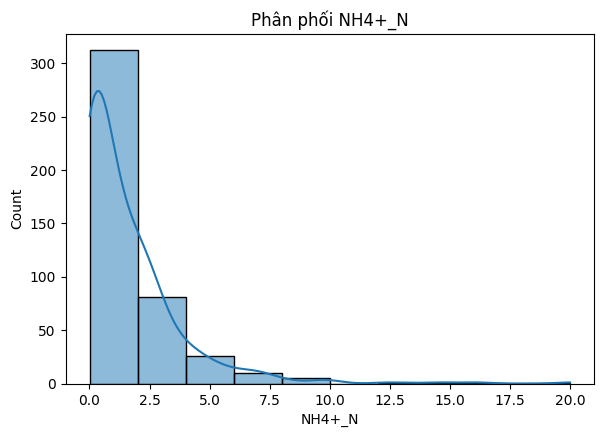

In [7]:
plt.figure(figsize=(15, 10))
# Biểu đồ phân phối cho Nhiệt độ
plt.subplot(2, 2, 1)
sns.histplot(final_data['NH4+_N'], bins=10, kde=True)
plt.title('Phân phối NH4+_N')

Trục hoành: Đại diện cho các giá trị của NH4+_N trong mẫu nước.

Trục tung: Đại diện cho số lượng mẫu (Count) trong từng khoảng giá trị của NH4+_N.

Nhận xét:

-	Hầu hết các giá trị NH4+_N tập trung quanh khoảng từ 0 đến 2, cho thấy đây là phạm vi phổ biến của nồng độ Ammonium trong mẫu nước.

-	Biểu đồ có hình dạng phân phối lệch phải (skewed right), nghĩa là phần lớn các giá trị NH4+_N có giá trị nhỏ, nhưng vẫn có một số mẫu có giá trị cao hơn.

-	Dữ liệu có một đỉnh rõ ràng ở khoảng 1.0, cho thấy một sự tập trung mạnh mẽ ở mức nồng độ này, nhưng vẫn có một số ít mẫu có giá trị NH4+_N lớn hơn, lên đến khoảng 20.

Text(0.5, 1.0, 'Phân phối NO2-_N')

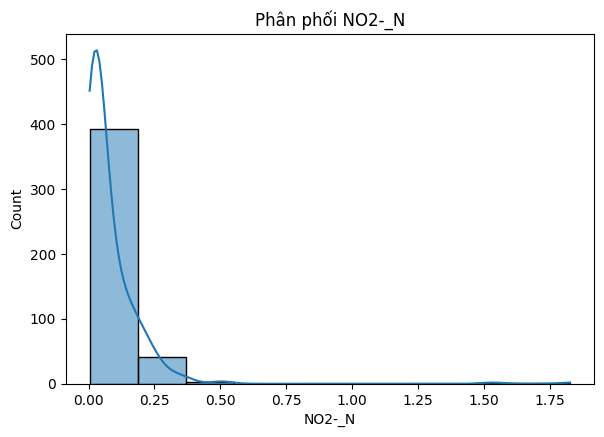

In [8]:
plt.figure(figsize=(15, 10))
# Biểu đồ phân phối cho NO2-_N
plt.subplot(2, 2, 2)
sns.histplot(final_data['NO2-_N'], bins=10, kde=True)
plt.title('Phân phối NO2-_N')

Trục hoành: Đại diện cho các giá trị của NO2-_N trong mẫu nước.

Trục tung: Đại diện cho số lượng mẫu trong từng khoảng giá trị của NO2-_N.

Nhận xét:

-	Hầu hết các giá trị NO2-_N tập trung quanh 0, cho thấy nồng độ Nitrit Nitrogen trong mẫu nước chủ yếu thấp.

-	Biểu đồ có hình dạng phân phối lệch phải (skewed right), với phần lớn các giá trị NO2-_N nằm ở mức rất thấp. Một số ít mẫu có giá trị cao hơn, nhưng số lượng này rất hạn chế.

-	Đỉnh của phân phối nằm ở gần 0, với một số ít giá trị cao hơn, cho thấy Nitrit Nitrogen chủ yếu không hiện diện trong mẫu nước, và chỉ có một vài mẫu nước có nồng độ Nitrit Nitrogen cao.

Text(0.5, 1.0, 'Phân phối Nhiệt độ')

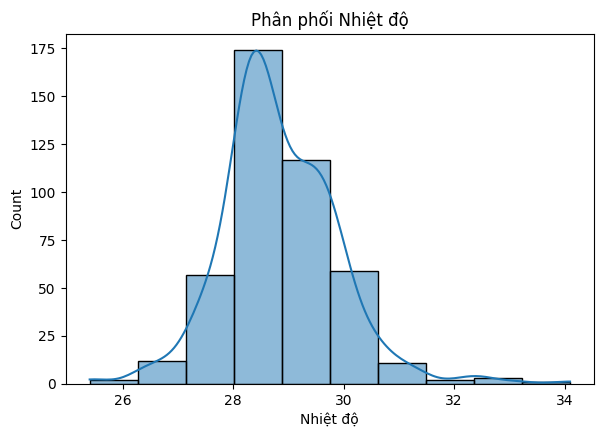

In [9]:
plt.figure(figsize=(15, 10))
# Biểu đồ phân phối cho Nhiệt độ
plt.subplot(2, 2, 1)
sns.histplot(final_data['Nhiệt độ'], bins=10, kde=True)
plt.title('Phân phối Nhiệt độ')


Trục hoành (x-axis): Giá trị Nhiệt độ (°C).

Trục tung (y-axis): Số lượng mẫu (Count) trong từng khoảng giá trị nhiệt độ.

Đường màu xanh: Đường phân phối xác suất (KDE) cho thấy xu hướng phân bố của dữ liệu.

Nhận xét:
Hầu hết các giá trị Nhiệt độ tập trung quanh khoảng 28.0°C đến 28.5°C, cho thấy đây là nhiệt độ phổ biến trong các mẫu nước được thu thập.
Sự phân phối có hình dạng gần như chuông, với một số giá trị cực trị ở hai bên, có thể chỉ ra sự biến động của nhiệt độ trong các điều kiện môi trường khác nhau.


Text(0.5, 1.0, 'Phân phối pH')

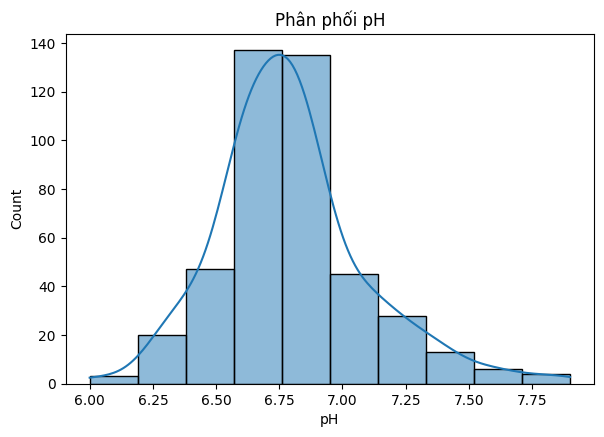

In [10]:
plt.figure(figsize=(15, 10))
# Biểu đồ phân phối cho pH
plt.subplot(2, 2, 2)
sns.histplot(final_data['pH'], bins=10, kde=True)
plt.title('Phân phối pH')

Trục hoành: Giá trị pH.

Trục tung: Số lượng mẫu trong từng khoảng giá trị pH.

Nhận xét:

Hầu hết các giá trị pH nằm trong khoảng từ 6.5 đến 7.5, cho thấy nước trong khu vực này có độ pH tương đối ổn định và phù hợp với tiêu chuẩn môi trường.

Đường phân phối cho thấy rằng hầu hết các mẫu có pH khoảng 6.8, cho thấy môi trường nước có tính kiềm nhẹ.

Text(0.5, 1.0, 'Phân phối DO')

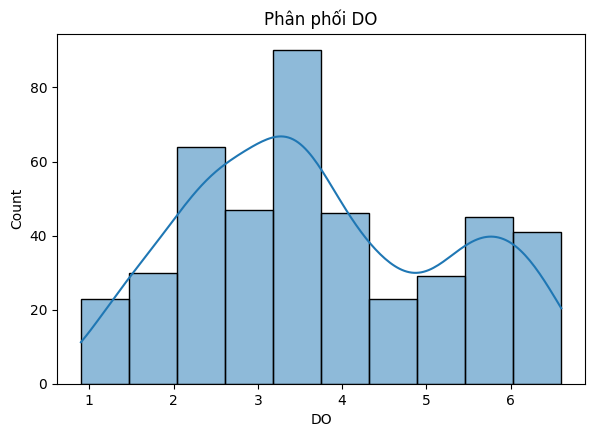

In [11]:
plt.figure(figsize=(15, 10))
# Biểu đồ phân phối cho DO
plt.subplot(2, 2, 3)
sns.histplot(final_data['DO'], bins=10, kde=True)
plt.title('Phân phối DO')

Trục hoành: Giá trị DO (mg/l).

Trục tung: Số lượng mẫu trong từng khoảng giá trị DO.
Nhận xét:


Giá trị DO có sự biến động lớn, với các giá trị chủ yếu tập trung ở khoảng từ 2 đến 5 mg/l.

Đường phân phối cho thấy rằng có nhiều mẫu với DO thấp, điều này có thể chỉ ra rằng một số khu vực trong nghiên cứu có thể bị ô nhiễm hoặc có ít oxy hòa tan hơn, ảnh hưởng đến sự sống của các sinh vật dưới nước.

Text(0.5, 1.0, 'Phân phối COD')

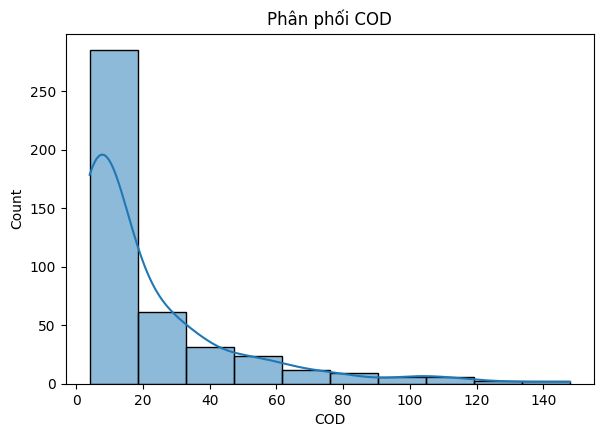

In [12]:
plt.figure(figsize=(15, 10))
# Biểu đồ phân phối cho COD
plt.subplot(2, 2, 3)
sns.histplot(final_data['COD'], bins=10, kde=True)
plt.title('Phân phối COD')

Trục hoành: Giá trị COD (mg/l).

Trục tung: Số lượng mẫu trong từng khoảng giá trị COD.

Nhận xét:

-	Giá trị COD phân bố không đồng đều, tập trung chủ yếu ở khoảng 0 đến 20 mg/l, với số lượng mẫu giảm dần khi giá trị COD tăng.

-	Đường phân phối cho thấy phần lớn các mẫu có giá trị COD thấp, phản ánh mức độ ô nhiễm hữu cơ nhẹ tại nhiều khu vực. Tuy nhiên, vẫn có một số ít mẫu với giá trị COD cao (> 60 mg/l), điều này có thể là dấu hiệu của các khu vực bị ô nhiễm nặng do nước thải chứa nhiều chất hữu cơ từ các nguồn công nghiệp, nông nghiệp hoặc sinh hoạt.

-	Việc kiểm soát các nguồn thải này là cần thiết để đảm bảo chất lượng nước và giảm thiểu nguy cơ ô nhiễm môi trường.

Text(0.5, 1.0, 'Phân phối Coliform')

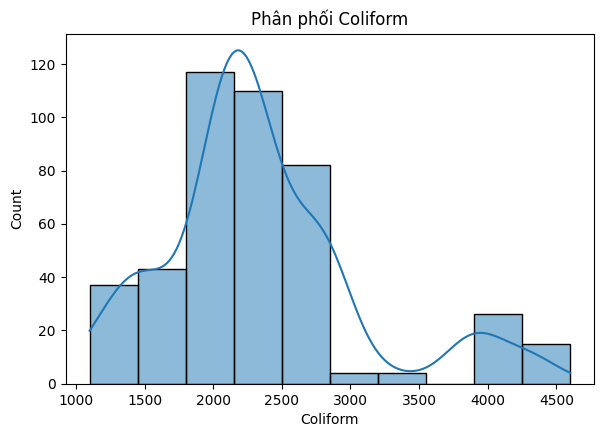

In [13]:
plt.figure(figsize=(15, 10))
# Biểu đồ phân phối cho Coliform
plt.subplot(2, 2, 4)
sns.histplot(final_data['Coliform'], bins=10, kde=True)
plt.title('Phân phối Coliform')

Trục hoành: Giá trị Coliform (MPN/100ml).

Trục tung: Số lượng mẫu trong từng khoảng giá trị Coliform.
Nhận xét:

Số lượng Coliform trong mẫu có sự phân bố không đồng đều, với phần lớn mẫu có giá trị khoảng từ 1000 đến 2500 MPN/100ml.

Điều này cho thấy có khả năng ô nhiễm vi sinh vật trong nước, vì Coliform là chỉ số quan trọng cho chất lượng nước và thường được sử dụng để kiểm tra mức độ ô nhiễm.

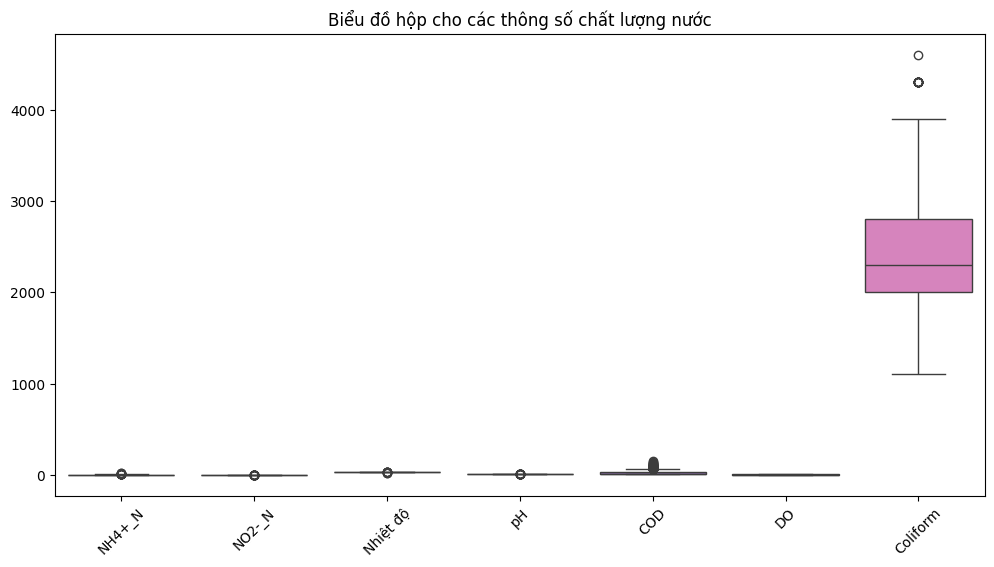

In [14]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=final_data[['NH4+_N', 'NO2-_N', 'Nhiệt độ', 'pH','COD' ,'DO', 'Coliform']])
plt.title('Biểu đồ hộp cho các thông số chất lượng nước')
plt.xticks(rotation=45)
plt.show()

Trục hoành: Đại diện cho các thông số chất lượng nước: NH4+_N, NO2-_N, Nhiệt độ, pH, DO, COD và Coliform.
Trục tung: Đại diện cho giá trị của từng thông số.

Cấu trúc của biểu đồ hộp:

-	Phần giữa của hộp: Đại diện cho khoảng giữa (interquartile range - IQR) của dữ liệu, nơi 50% dữ liệu nằm giữa Q1 (25th percentile) và Q3 (75th percentile).

-	Đường giữa hộp: Thể hiện giá trị trung vị (median) của dữ liệu.

-	Các đường kẻ (whiskers): Chỉ ra sự phân bố của dữ liệu nằm ngoài khoảng IQR, thường là từ Q1 - 1.5 * IQR đến Q3 + 1.5 * IQR.

-	Các điểm ngoài (outliers): Các giá trị nằm ngoài đường kẻ whiskers, cho thấy những giá trị cực trị trong dữ liệu.

-	NH4+_N và NO2-_N: Các chỉ số này có phân phối rất hẹp, với phần lớn các giá trị nằm gần mức 0. Không có giá trị ngoại lai rõ ràng, điều này có thể cho thấy nồng độ NH4+_N và NO2-_N trong mẫu nước ở mức thấp và ổn định.

-	Nhiệt độ: Giá trị của Nhiệt độ nằm trong khoảng hẹp và không có giá trị ngoại lai rõ ràng. Điều này cho thấy Nhiệt độ trong các mẫu nước ổn định, không có sự biến động lớn.

-	pH: Phân phối pH cũng hẹp, với trung vị khoảng 6.5 đến 7.5. Không có giá trị ngoại lai đáng chú ý, cho thấy chất lượng nước khá ổn định về độ pH, không có sự thay đổi đáng kể trong môi trường nước.

-	DO: Phân phối DO có thể cho thấy một số biến động, nhưng nhìn chung giá trị không có giá trị ngoại lai lớn. Điều này có thể chỉ ra rằng nước trong khu vực nghiên cứu vẫn đủ oxy hòa tan cho các sinh vật sống, tuy nhiên có thể có sự biến động nhẹ.

-	COD: Phân phối COD có thể cho thấy sự biến động lớn hơn, với một số giá trị ngoại lai. Điều này có thể chỉ ra rằng một số khu vực có mức độ ô nhiễm hữu cơ cao, cần được kiểm tra và xử lý kịp thời để bảo vệ chất lượng nước.

-	Coliform: Phân phối của Coliform cho thấy có sự biến động lớn với một số giá trị ngoại lai. Điều này có thể chỉ ra rằng một số khu vực có mức ô nhiễm vi sinh vật cao hơn. Đây là vấn đề cần được chú ý trong việc quản lý chất lượng nước, vì mức độ Coliform cao có thể ảnh hưởng đến sức khỏe cộng đồng.

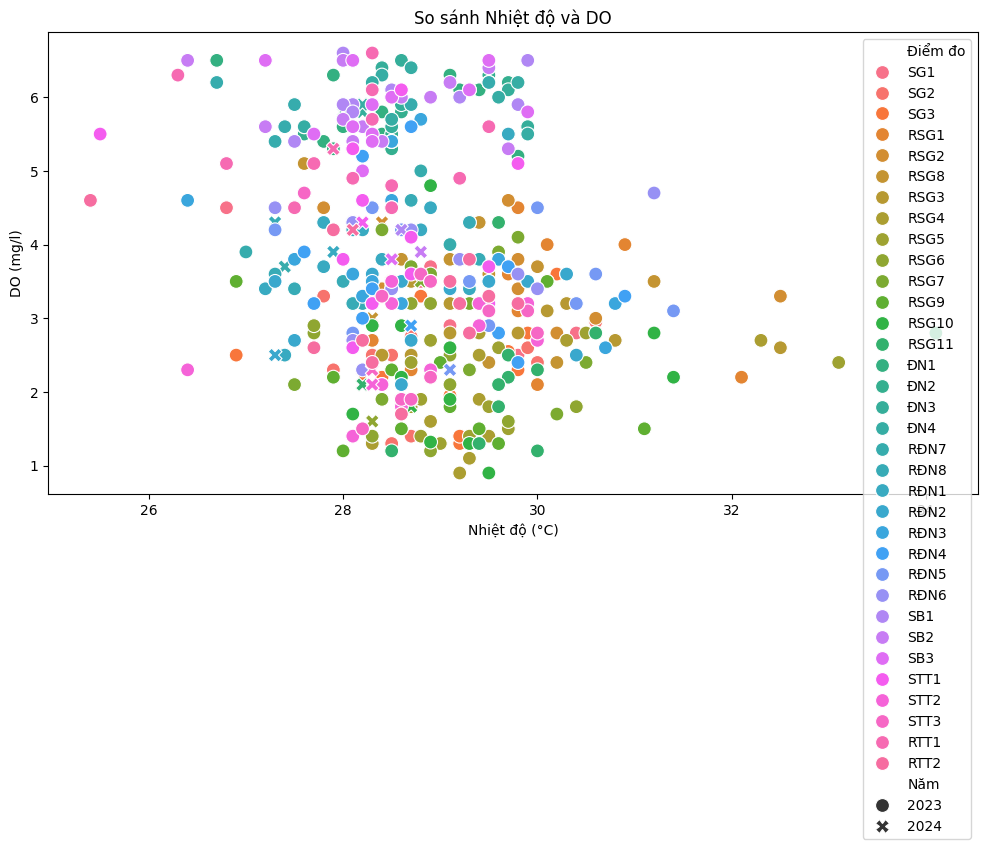

In [15]:
plt.figure(figsize=(12, 6))
sns.scatterplot(data=final_data, x='Nhiệt độ', y='DO', hue='Điểm đo', style='Năm', s=100)
plt.title('So sánh Nhiệt độ và DO')
plt.xlabel('Nhiệt độ (°C)')
plt.ylabel('DO (mg/l)')
plt.legend()
plt.show()

Trục hoành: Đại diện cho giá trị Nhiệt độ (°C).

Trục tung: Đại diện cho hàm lượng DO (mg/l).

Màu sắc của điểm: Thể hiện các Điểm đo khác nhau (SG1, SG2, RSG3, …), giúp phân biệt các khu vực lấy mẫu khác nhau.

Kích thước điểm: Có thể đại diện cho các năm (2023 và 2024), cho thấy sự phân bố của các mẫu nước qua các năm.

Nhận xét về mối quan hệ giữa Nhiệt độ và DO:

-	Xu hướng tổng thể: Biểu đồ cho thấy rằng hàm lượng DO có sự biến động nhưng không có mối tương quan mạnh mẽ với Nhiệt độ. Một số mẫu có nhiệt độ cao nhưng hàm lượng DO lại thấp, điều này có thể chỉ ra rằng trong các điều kiện khác nhau (như ô nhiễm hoặc cấu trúc sinh thái), DO không hoàn toàn phụ thuộc vào nhiệt độ.

-	Độ phân bố của các điểm: Có nhiều điểm nằm trong khoảng nhiệt độ từ 27.5 đến 29.5°C, cho thấy đây là phạm vi nhiệt độ phổ biến trong các mẫu nước.

-	DO có giá trị biến động, với nhiều điểm nằm dưới 3 mg/l, điều này có thể là chỉ số cho thấy môi trường nước có thể không đủ oxy hòa tan, gây ảnh hưởng đến sự sống của sinh vật thủy sinh.


Chia dữ liệu thành tập huấn luyện và kiểm tra: Sử dụng phương pháp train_test_split từ scikit-learn.

In [16]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [17]:
# Chia dữ liệu thành tập huấn luyện và kiểm tra
from sklearn.model_selection import train_test_split 

# Tách lại X và y
X = final_data[['NH4+_N', 'NO2-_N', 'pH', 'DO', 'Coliform', 'COD']]  # Các đặc trưng
y = final_data['WQI']  # Chỉ số WQI

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Số lượng mẫu trong X:", len(X))
print("Số lượng mẫu trong y:", len(y))


Số lượng mẫu trong X: 438
Số lượng mẫu trong y: 438


In [18]:
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression

# Mô hình Random Forest
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Dự đoán trên tập kiểm tra
rf_pred = rf_model.predict(X_test)

# Mô hình Hồi quy tuyến tính
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Dự đoán trên tập kiểm tra
lr_pred = lr_model.predict(X_test)

# Mô hình Gradient Boosting
gb_model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gb_model.fit(X_train, y_train)

# Dự đoán trên tập kiểm tra
gb_pred = gb_model.predict(X_test)


In [19]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("Random Forest - MSE:", mean_squared_error(y_test, rf_pred))
print("Random Forest - RMSE:", np.sqrt(mean_squared_error(y_test, rf_pred)))
print("Random Forest - MAE:", mean_absolute_error(y_test, rf_pred))
print("Random Forest - R^2:", r2_score(y_test, rf_pred))

print("\n" + "="*50 + "\n")

print("Linear Regression - MSE:", mean_squared_error(y_test, lr_pred))
print("Linear Regression - RMSE:", np.sqrt(mean_squared_error(y_test, lr_pred)))
print("Linear Regression - MAE:", mean_absolute_error(y_test, lr_pred))
print("Linear Regression - R^2:", r2_score(y_test, lr_pred))

print("\n" + "="*50 + "\n")

print("Gradient Boosting - MSE:", mean_squared_error(y_test, gb_pred))
print("Gradient Boosting - RMSE:", np.sqrt(mean_squared_error(y_test, gb_pred)))
print("Gradient Boosting - MAE:", mean_absolute_error(y_test, gb_pred))
print("Gradient Boosting - R^2:", r2_score(y_test, gb_pred))

Random Forest - MSE: 0.20027514862897403
Random Forest - RMSE: 0.4475211152884007
Random Forest - MAE: 0.29413425575042124
Random Forest - R^2: 0.9807535366941108


Linear Regression - MSE: 4.260846806374707
Linear Regression - RMSE: 2.0641818733761585
Linear Regression - MAE: 1.38118037062229
Linear Regression - R^2: 0.590532164013873


Gradient Boosting - MSE: 0.11095579650519495
Gradient Boosting - RMSE: 0.33310027995364244
Gradient Boosting - MAE: 0.18395683242497068
Gradient Boosting - R^2: 0.9893371360319441


In [20]:
from sklearn.model_selection import GridSearchCV

# Định nghĩa phạm vi các tham số cho RandomForest
rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30],
    'min_samples_split': [5, 10, 15]
}

# Khởi tạo GridSearchCV cho RandomForest
rf_grid_search = GridSearchCV(RandomForestRegressor(random_state=42), rf_param_grid, cv=5, n_jobs=-1)
rf_grid_search.fit(X_train, y_train)

# Lấy siêu tham số tốt nhất từ GridSearchCV
best_rf_params = rf_grid_search.best_params_
print("Thông số tốt nhất cho RandomForest:", best_rf_params)

Thông số tốt nhất cho RandomForest: {'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 200}


In [21]:
# Định nghĩa phạm vi các tham số cho GradientBoosting
gb_param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7]
}

# Khởi tạo GridSearchCV cho GradientBoosting
gb_grid_search = GridSearchCV(GradientBoostingRegressor(random_state=42), gb_param_grid, cv=5, n_jobs=-1)
gb_grid_search.fit(X_train, y_train)

# Lấy siêu tham số tốt nhất từ GridSearchCV
best_gb_params = gb_grid_search.best_params_
print("Thông số tốt nhất cho GradientBoosting:", best_gb_params)

Thông số tốt nhất cho GradientBoosting: {'learning_rate': 0.2, 'max_depth': 3, 'n_estimators': 200}


In [22]:
from sklearn.ensemble import StackingRegressor

# Mô hình đã được tối ưu 
optimized_models = {
    'RandomForest': RandomForestRegressor(**best_rf_params),
    'LinearRegression': LinearRegression(),
    'GradientBoosting': GradientBoostingRegressor(**best_gb_params)
}

# Mô hình meta - đây là mô hình học kết hợp
meta_model = LinearRegression()

# Tạo mô hình StackingRegressor với các mô hình cơ sở và mô hình meta
stacking_model = StackingRegressor(
    estimators=[('rf', optimized_models['RandomForest']),
                ('lr', optimized_models['LinearRegression']),
                ('gb', optimized_models['GradientBoosting'])],
    final_estimator=meta_model
)

# Huấn luyện mô hình stacking trên dữ liệu huấn luyện (X_train và y_train)
stacking_model.fit(X_train, y_train)

# Dự đoán trên tập dữ liệu test (X_test)
sm_pred = stacking_model.predict(X_test)


In [23]:
print("Stacking Model - MSE:", mean_squared_error(y_test, sm_pred))
print("Stacking Model - RMSE:", np.sqrt(mean_squared_error(y_test, sm_pred)))
print("Stacking Model - MAE:", mean_absolute_error(y_test, sm_pred))
print("Stacking Model - R^2:", r2_score(y_test, sm_pred))

Stacking Model - MSE: 0.10474289124472543
Stacking Model - RMSE: 0.3236400643380319
Stacking Model - MAE: 0.1839129917192247
Stacking Model - R^2: 0.9899341968951474


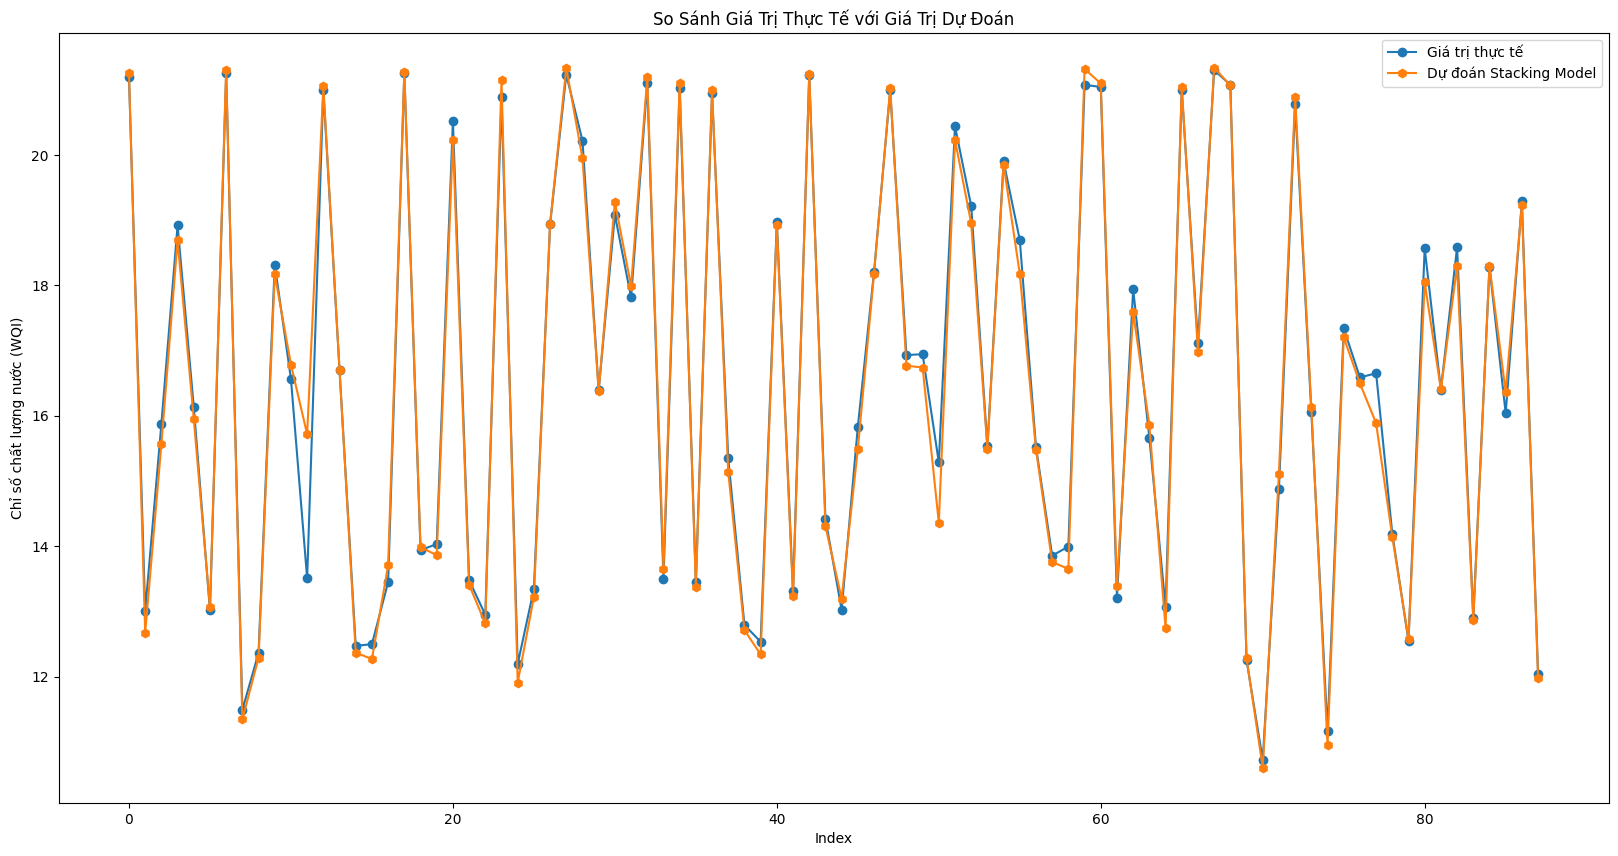

In [24]:
plt.figure(figsize=(20, 10))
plt.plot(y_test.values, label='Giá trị thực tế', marker='o')
plt.plot(sm_pred, label='Dự đoán Stacking Model', marker='h')
plt.title('So Sánh Giá Trị Thực Tế với Giá Trị Dự Đoán')
plt.xlabel('Index')
plt.ylabel('Chỉ số chất lượng nước (WQI)')
plt.legend()
plt.show()

Trục hoành: Đại diện cho chỉ số mẫu (Index), thể hiện thứ tự của các điểm trong tập kiểm tra.

Trục tung: Đại diện cho chỉ số chất lượng nước (WQI). 

Các điểm dữ liệu: 

-	Giá trị thực tế (thể hiện bằng hình tròn): Đại diện cho các giá trị thực tế của WQI.

-	Dự đoán từ mô hình Random Forest (hình thập tự): Các điểm thể hiện giá trị WQI dự đoán bởi mô hình Random Forest.

-	Dự đoán từ mô hình Hồi quy tuyến tính (hình vuông): Các điểm thể hiện giá trị WQI dự đoán bởi mô hình Hồi quy tuyến tính.

Nhận xét về mối quan hệ giữa các dự đoán và giá trị thực tế

•	Sự tương đồng: Có thể thấy rằng cả hai mô hình đều cố gắng theo dõi các biến động của giá trị thực tế. Tuy nhiên, có một số điểm mà các mô hình không đạt được sự chính xác cao.

•	Random Forest: Tương đối gần giống với giá trị thực tế, mặc dù có một vài điểm lệch nhưng nhìn chung mô hình phản ánh tốt các xu hướng của dữ liệu thực tế. Mô hình này thường có độ chính xác cao hơn và có thể phản ánh sự biến động trong dữ liệu tốt hơn so với hồi quy tuyến tính, điều này có thể do khả năng của trong việc xử lý các mối quan hệ phi tuyến tính.

•	Hồi quy tuyến tính: Thể hiện một sự khác biệt rõ rệt so với giá trị thực tế. Mô hình có thể không phản ánh tốt tất cả các biến động, đặc biệt là ở các điểm dữ liệu có giá trị cực trị. Điều này có thể do giả định về mối quan hệ tuyến tính giữa các biến độc lập và phụ thuộc.

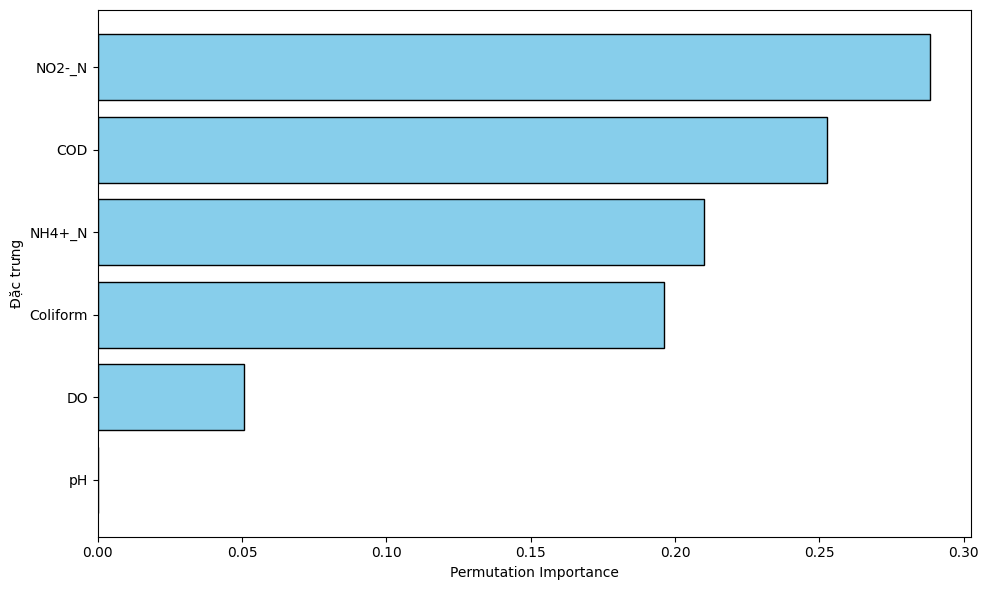

In [25]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import numpy as np

# Tính toán Permutation Importance
perm_importance = permutation_importance(stacking_model, X_test, y_test, n_repeats=30, random_state=42)

# Lấy giá trị trung bình và sắp xếp tầm quan trọng
sorted_idx = perm_importance.importances_mean.argsort()

# Vẽ biểu đồ
plt.figure(figsize=(10, 6))
plt.barh(X_test.columns[sorted_idx], perm_importance.importances_mean[sorted_idx], color="skyblue", edgecolor="black")
plt.xlabel("Permutation Importance")
plt.ylabel("Đặc trưng")
plt.tight_layout()
plt.show()


Biểu đồ trên cho thấy các chất gây ô nhiễm chính ảnh hưởng đến chất lượng nước. Yếu tố quan trọng nhất là NO2-N (Nitrit), chủ yếu đến từ phân bón nông nghiệp, nước thải chăn nuôi, sinh hoạt và các hoạt động công nghiệp chưa được xử lý, cho thấy mức độ ô nhiễm hóa học nghiêm trọng. Tiếp theo là NH4+-N (Amoni), một chỉ số quan trọng phản ánh sự phân hủy hữu cơ và ô nhiễm từ chất thải nông nghiệp, chăn nuôi. COD (Nhu cầu oxy hóa học) cũng đóng vai trò lớn, phản ánh sự hiện diện của các chất hữu cơ và hóa chất khó phân hủy trong nước, thường xuất phát từ nước thải công nghiệp, nông nghiệp và sinh hoạt.
Ngoài ra, Coliform là một chỉ số vi sinh cho thấy sự hiện diện của vi khuẩn gây ô nhiễm từ nước thải sinh hoạt, chăn nuôi chưa được xử lý, với mức độ ảnh hưởng lớn trong việc đánh giá ô nhiễm vi sinh. DO (Oxy hòa tan), mặc dù có mức độ ảnh hưởng thấp hơn, vẫn là một yếu tố quan trọng liên quan đến khả năng hỗ trợ sự sống của các sinh vật thủy sinh. Cuối cùng, pH có ảnh hưởng nhỏ nhất trong biểu đồ, nhưng vẫn đóng vai trò quan trọng trong việc duy trì sự cân bằng hóa học của nước. Những chỉ số này cung cấp thông tin cần thiết để xác định các yếu tố cần can thiệp nhằm cải thiện chất lượng nước.

Mô hình đề xuất kết hợp ba thuật toán Linear Regression, RandomForestRegressor và GradientBoostingRegressor để tối ưu hóa hiệu suất dự đoán chất lượng nước. Phương pháp Permutation Feature Importance được áp dụng để đánh giá tầm quan trọng của các chỉ tiêu bằng cách xáo trộn giá trị của từng đặc trưng trong dữ liệu kiểm tra và đo lường mức độ ảnh hưởng đến hiệu suất mô hình. Kết quả phân tích cho thấy các chỉ tiêu chính bao gồm NO2-N, NH4+-N, COD, Coliform, DO và pH. Trong đó, NO2-N và NH4+-N là những yếu tố ảnh hưởng lớn nhất, chủ yếu đến từ phân bón nông nghiệp, nước thải chăn nuôi và sinh hoạt. COD phản ánh mức độ ô nhiễm hữu cơ từ nước thải công nghiệp và sinh hoạt, trong khi Coliform thể hiện sự hiện diện của vi khuẩn từ nước thải chưa qua xử lý. DO bị ảnh hưởng bởi mức độ ô nhiễm hữu cơ, và pH là yếu tố quan trọng để duy trì sự cân bằng hóa học trong nước. Để cải thiện chất lượng nước, cần ưu tiên giảm tải các yếu tố như NO2-N, NH4+-N, COD và Coliform thông qua quản lý phân bón nông nghiệp, xử lý nước thải công nghiệp và sinh hoạt. Ngoài ra, việc kiểm soát lượng ô nhiễm hữu cơ (COD, BOD5) sẽ giúp cải thiện lượng oxy hòa tan (DO), đồng thời duy trì sự ổn định của chỉ số pH. Các giải pháp này, kết hợp với kết quả dự đoán từ mô hình, sẽ hỗ trợ các cơ quan quản lý đưa ra chiến lược xử lý phù hợp nhằm nâng cao chỉ số chất lượng nước 


Dự đoán cho tương lai

In [26]:
future_data = pd.DataFrame({
    'NH4+_N': [0.03, 0.025, 0.01],
    'NO2-_N': [0.05, 0.06, 0.001],
    'pH': [7, 8, 6],
    'DO': [8, 4, 6],
    'Coliform': [10, 20, 100],
    'COD': [5, 8, 1]
})

In [27]:
# Bước 2: Dự đoán WQI cho dữ liệu tương lai
future_predictions_rf = rf_model.predict(future_data)
future_predictions_lr = lr_model.predict(future_data)
future_predictions_gb = gb_model.predict(future_data)
future_predictions_sm = stacking_model.predict(future_data)

# Thêm kết quả dự đoán vào DataFrame
future_data['WQI_RF'] = future_predictions_rf
future_data['WQI_LR'] = future_predictions_lr
future_data['WQI_GB'] = future_predictions_gb
future_data['WQI_SM'] = future_predictions_sm


# Hiển thị dự đoán cho năm 2025
print("Dự đoán WQI cho năm 2025:")
print(future_data)

Dự đoán WQI cho năm 2025:
   NH4+_N  NO2-_N  pH  DO  Coliform  COD     WQI_RF     WQI_LR     WQI_GB  \
0   0.030   0.050   7   8        10    5  20.720870  24.328002  20.273297   
1   0.025   0.060   8   4        20    8  18.989342  21.026386  19.135791   
2   0.010   0.001   6   6       100    1  21.143126  22.863334  21.147789   

      WQI_SM  
0  20.341201  
1  19.113555  
2  21.309506  


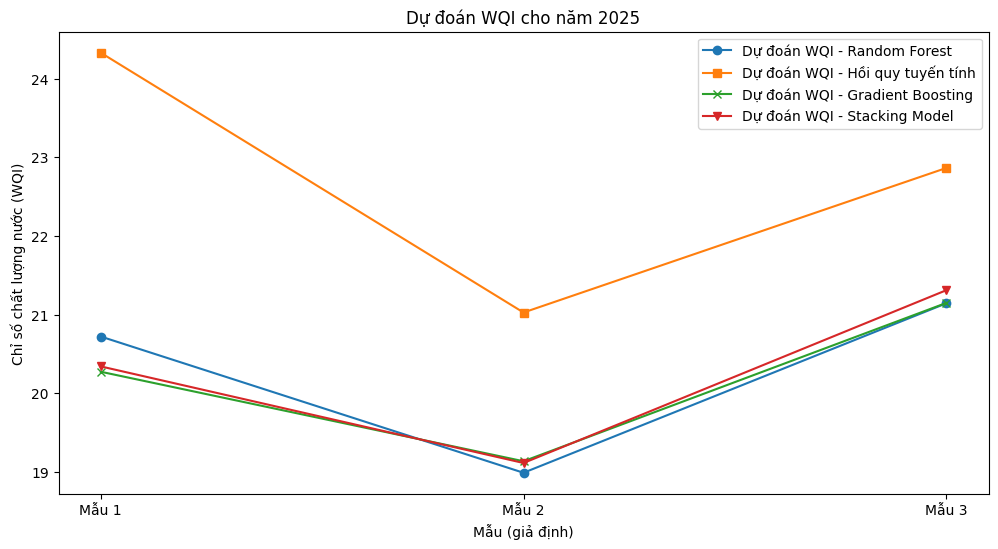

In [28]:
# Vẽ biểu đồ dự đoán cho năm 2025
plt.figure(figsize=(12, 6))
plt.plot(future_data.index, future_data['WQI_RF'], label='Dự đoán WQI - Random Forest', marker='o')
plt.plot(future_data.index, future_data['WQI_LR'], label='Dự đoán WQI - Hồi quy tuyến tính', marker='s')
plt.plot(future_data.index, future_data['WQI_GB'], label='Dự đoán WQI - Gradient Boosting', marker='x')
plt.plot(future_data.index, future_data['WQI_SM'], label='Dự đoán WQI - Stacking Model', marker='v')
plt.title('Dự đoán WQI cho năm 2025')
plt.xlabel('Mẫu (giả định)')
plt.ylabel('Chỉ số chất lượng nước (WQI)')
plt.xticks(future_data.index, ['Mẫu 1', 'Mẫu 2', 'Mẫu 3'])
plt.legend()
plt.show()

Trục hoành (X): Đại diện cho chỉ số mẫu, thể hiện thứ tự của các điểm trong tập kiểm tra.

Trục tung (Y): Đại diện cho chỉ số chất lượng nước (WQI).

Các điểm dữ liệu:

- Giá trị thực tế (hình tròn): Đại diện cho các giá trị WQI thực tế.

- Dự đoán từ mô hình Random Forest (hình thập tự): Các điểm thể hiện giá trị WQI dự đoán bởi mô hình Random Forest.

- Dự đoán từ mô hình Hồi quy tuyến tính (hình vuông): Các điểm thể hiện giá trị WQI dự đoán bởi mô hình Hồi quy tuyến tính.

- Dự đoán từ mô hình Gradient Boosting và Stacking Model: Các điểm thể hiện trên biểu đồ với sự ổn định và tương đồng, biểu thị hiệu quả của các mô hình phi tuyến.

Sự tương đồng:

Cả bốn mô hình (Random Forest, Hồi quy tuyến tính, Gradient Boosting và Stacking Model) đều dự đoán WQI cho các mẫu trong năm 2025 với các giá trị gần nhau (ngoại trừ hồi quy tuyến tính). Điều này cho thấy các mô hình đang phản ánh một xu hướng chung trong dữ liệu chất lượng nước.

Xu hướng:

Hầu hết các mô hình đều cho thấy xu hướng giảm nhẹ từ Mẫu 1 đến Mẫu 2 và tăng trở lại ở Mẫu 3. Điều này có thể cho thấy biến động chất lượng nước tại các mẫu, có khả năng phản ánh sự thay đổi trong điều kiện môi trường hoặc nguồn thải.

Độ chính xác:

Mô hình Gradient Boosting và Stacking Model có xu hướng đưa ra các dự đoán ổn định và gần nhau hơn so với Hồi quy tuyến tính, vốn có độ chênh lệch lớn giữa các mẫu. Random Forest cũng cho ra kết quả ổn định, cho thấy phù hợp với dữ liệu phi tuyến. Hồi quy tuyến tính tỏ ra kém hiệu quả hơn khi xử lý dữ liệu có yếu tố phức tạp hoặc phi tuyến.

Giá trị cụ thể:

Nếu so sánh các giá trị cụ thể trong biểu đồ, Gradient Boosting, Random Forest và Stacking Model cho ra các giá trị tương đồng, nằm trong khoảng 19-21 cho cả ba mẫu. Hồi quy tuyến tính lại chênh lệch lớn hơn, đặc biệt ở Mẫu 1 và Mẫu 3 (vượt ngưỡng 24). Điều này nhấn mạnh sự cần thiết phải áp dụng các mô hình phi tuyến để có dự đoán chính xác hơn.